# Forecasting the US yield curve with Dynamic Nelson-Siegel

A short walkthrough of the method: fit the curve with three factors, model the factors over time, and check whether this forecasts better than the naive "no change" benchmark.

The full results (all models, the Kalman filter version, significance tests) are produced by `run_all.py` and summarised in the README.

In [1]:
import sys; sys.path.insert(0, "..")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from dnsmodel import MATURITIES, load_yields, nelson_siegel_loadings, fit_factors, TwoStepDNS
from dnsmodel.backtest import random_walk, expanding_window_errors, rmse

y = load_yields()
print(y.shape, y.index[0].date(), "->", y.index[-1].date())
y.iloc[:3, :8]

(348, 17) 1972-01-31 -> 2000-12-31


,3,6,9,12,15,18,21,24
date,,,,,,,,
1972-01-31,3.382,3.782,3.995,4.120,4.442,4.595,4.714,4.804
1972-02-29,3.470,3.831,3.983,4.291,4.391,4.443,4.626,4.769
1972-03-31,3.874,4.463,4.663,4.937,5.141,5.317,5.466,5.528


## 1. Three factors describe the whole curve

Nelson-Siegel writes the yield at maturity $\tau$ as

$$y(\tau) = \beta_1 + \beta_2 \frac{1-e^{-\lambda\tau}}{\lambda\tau} + \beta_3 \left(\frac{1-e^{-\lambda\tau}}{\lambda\tau} - e^{-\lambda\tau}\right)$$

With $\lambda$ fixed at 0.0609 (Diebold & Li, 2006), the loadings are known and each month's $\beta$ is a simple OLS regression.

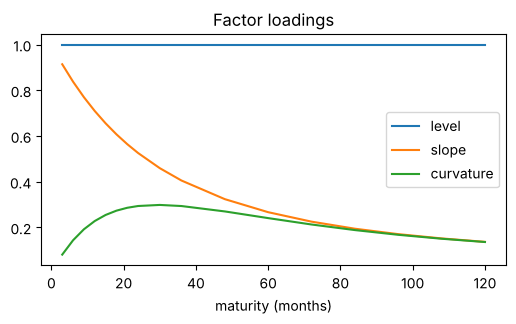

In [2]:
Z = nelson_siegel_loadings(0.0609, MATURITIES)
fig, ax = plt.subplots(figsize=(6, 3))
for j, name in enumerate(["level", "slope", "curvature"]):
    ax.plot(MATURITIES, Z[:, j], label=name)
ax.set_xlabel("maturity (months)"); ax.set_title("Factor loadings"); ax.legend();

In-sample RMSE: 10.2 bp on average across maturities


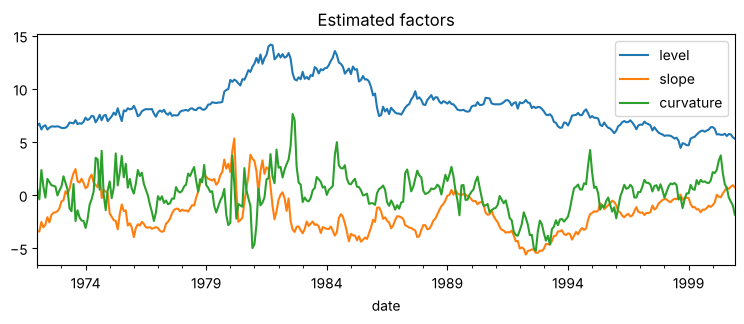

In [3]:
betas, fitted = fit_factors(y.values, Z)
print(f"In-sample RMSE: {rmse(y.values - fitted).mean() * 100:.1f} bp on average across maturities")
pd.DataFrame(betas, index=y.index, columns=["level", "slope", "curvature"]).plot(figsize=(9, 3), title="Estimated factors");

## 2. Out-of-sample: does it beat the random walk?

From January 1994, each month we re-estimate the model on past data only, forecast the curve 1, 6 and 12 months ahead, and compare the errors with the random walk (tomorrow's curve = today's).

In [4]:
first = y.index.get_loc(pd.Timestamp("1994-01-31"))
errs = expanding_window_errors(y.values, {"Random walk": random_walk, "DNS": TwoStepDNS(Z, "ar1").forecast}, [1, 6, 12], first)
ratio = pd.DataFrame({f"{h}m ahead": rmse(errs["DNS"][h]) / rmse(errs["Random walk"][h]) for h in [1, 6, 12]},
                     index=MATURITIES.astype(int)).rename_axis("maturity (months)")
ratio.round(2).T

maturity (months),3,6,9,12,15,18,21,24,30,36,48,60,72,84,96,108,120
1m ahead,0.88,0.92,0.93,0.92,0.97,0.97,0.96,0.96,0.95,0.93,0.93,1.00,0.98,1.00,0.97,0.97,0.96
6m ahead,0.74,0.81,0.81,0.84,0.85,0.86,0.87,0.87,0.88,0.88,0.91,0.95,0.96,0.96,0.95,0.94,0.96
12m ahead,0.85,0.89,0.89,0.91,0.90,0.91,0.93,0.94,0.97,0.99,1.02,1.05,1.07,1.06,1.07,1.08,1.11


A ratio below 1 means DNS forecasts better than the random walk. The gain is largest for short maturities at the 6-month horizon; at 12 months, long yields are better forecast by the random walk. See the README for the significance tests and the other models.